# Loading te Dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
import joblib
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/project_for_online_class/bhutan_student_wellbeing.csv')
df.head()

,student_id,age,gender,district,residence,sleep_hours,study_hours_per_day,physical_activity_days,stress_level,social_support,financial_pressure,academic_pressure,screen_time_hours,mental_health_awareness,support_need
0,SYN0001,18,Female,Thimphu,Rural,7.6,5.5,5,7,7,10,1,4.9,Medium,Support recommended
1,SYN0002,24,Male,Wangdue Phodrang,Urban,7.6,3.2,7,10,5,3,4,5.5,Medium,Support recommended
2,SYN0003,23,Male,Mongar,Rural,6.8,5.8,6,6,3,10,3,8.6,Low,Support recommended
3,SYN0004,21,Female,Wangdue Phodrang,Rural,7.0,4.7,3,2,4,5,7,4.7,Medium,No immediate flag
4,SYN0005,21,Other / Prefer not to say,Samtse,Urban,5.3,3.8,4,10,1,9,9,5.3,Low,Support recommended


#**Exploratory Data Analysis(EDA)**

In [ ]:
# 1. Check the dataset size
print("Dataset shape:", df.shape)

Dataset shape: (800, 15)


In [ ]:
# 2.Check all column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['student_id', 'age', 'gender', 'district', 'residence', 'sleep_hours', 'study_hours_per_day', 'physical_activity_days', 'stress_level', 'social_support', 'financial_pressure', 'academic_pressure', 'screen_time_hours', 'mental_health_awareness', 'support_need']


In [ ]:
# 3.Descriptive statistics
print("\nNUMERICAL SUMMARY")
display(df.describe())


NUMERICAL SUMMARY


,age,sleep_hours,study_hours_per_day,physical_activity_days,stress_level,social_support,financial_pressure,academic_pressure,screen_time_hours
count,800.000000,800.000000,800.00000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000
mean,22.068750,6.860625,4.97475,3.517500,5.527500,5.45250,5.467500,5.676250,5.233375
std,2.582123,1.257184,1.96816,2.274568,2.833598,2.77847,2.849402,2.850718,2.040988
min,18.000000,3.200000,0.00000,0.000000,1.000000,1.00000,1.000000,1.000000,0.500000
25%,20.000000,6.000000,3.60000,2.000000,3.000000,3.00000,3.000000,3.000000,3.900000
50%,22.000000,6.800000,5.00000,4.000000,5.000000,5.00000,5.000000,6.000000,5.100000
75%,24.000000,7.725000,6.30000,5.000000,8.000000,8.00000,8.000000,8.000000,6.600000
max,26.000000,10.000000,11.20000,7.000000,10.000000,10.00000,10.000000,10.000000,11.600000


In [ ]:
# 4. Inspect data types and non-missing counts
print("\nDATASET INFORMATION")
df.info()


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               800 non-null    object 
 1   age                      800 non-null    int64  
 2   gender                   800 non-null    object 
 3   district                 800 non-null    object 
 4   residence                800 non-null    object 
 5   sleep_hours              800 non-null    float64
 6   study_hours_per_day      800 non-null    float64
 7   physical_activity_days   800 non-null    int64  
 8   stress_level             800 non-null    int64  
 9   social_support           800 non-null    int64  
 10  financial_pressure       800 non-null    int64  
 11  academic_pressure        800 non-null    int64  
 12  screen_time_hours        800 non-null    float64
 13  mental_health_awareness  800 non-null    object 
 14  suppo

In [ ]:
# 5. Checking the missing Values
df.isnull().sum()
# Calculate missing-value percentages
missing_percentage = (
    df.isnull().mean() * 100
).round(2)
missing_percentage

,0
student_id,0.0
age,0.0
gender,0.0
district,0.0
residence,0.0
sleep_hours,0.0
study_hours_per_day,0.0
physical_activity_days,0.0
stress_level,0.0
social_support,0.0


In [ ]:
# 6. Checking the Duplicates Values
df.duplicated().sum()

np.int64(0)

#Univariate Analysis of Categorical Variables

,count,mean,std,min,25%,50%,75%,max
age,800.0,22.068750,2.582123,18.0,20.0,22.0,24.000,26.0
sleep_hours,800.0,6.860625,1.257184,3.2,6.0,6.8,7.725,10.0
study_hours_per_day,800.0,4.974750,1.968160,0.0,3.6,5.0,6.300,11.2
physical_activity_days,800.0,3.517500,2.274568,0.0,2.0,4.0,5.000,7.0
stress_level,800.0,5.527500,2.833598,1.0,3.0,5.0,8.000,10.0
social_support,800.0,5.452500,2.778470,1.0,3.0,5.0,8.000,10.0
financial_pressure,800.0,5.467500,2.849402,1.0,3.0,5.0,8.000,10.0
academic_pressure,800.0,5.676250,2.850718,1.0,3.0,6.0,8.000,10.0
screen_time_hours,800.0,5.233375,2.040988,0.5,3.9,5.1,6.600,11.6


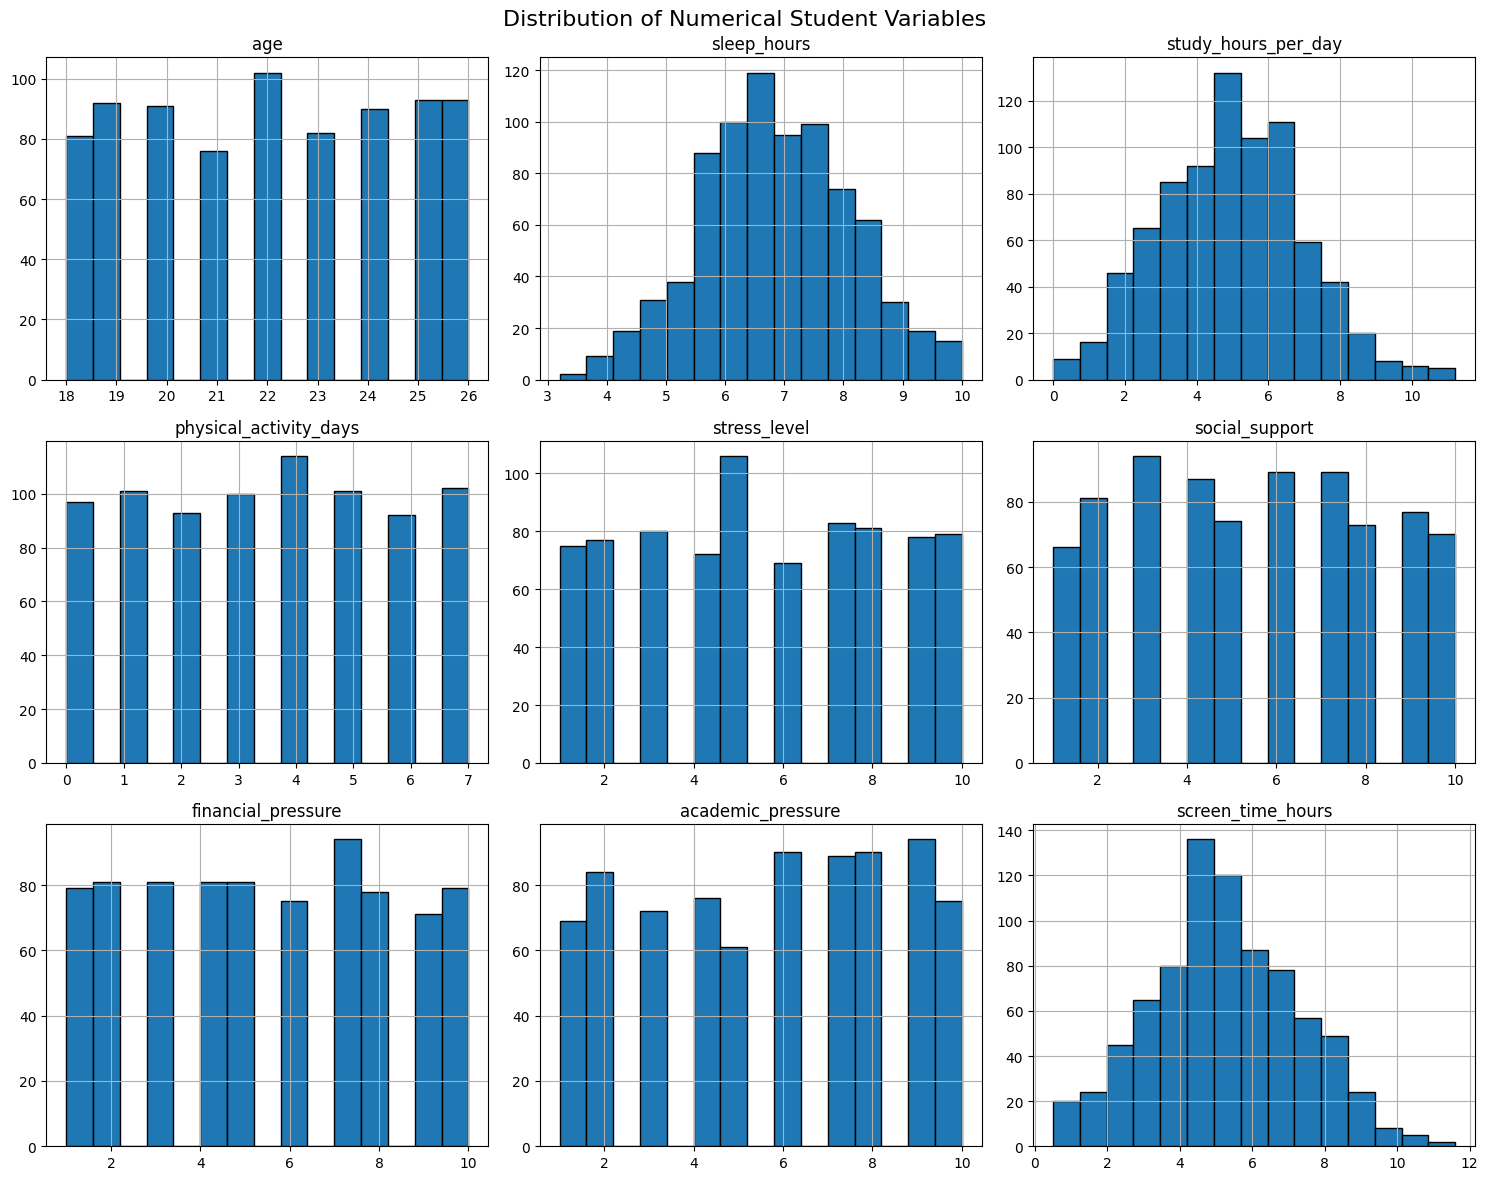

In [ ]:
numeric_cols = [
    "age",
    "sleep_hours",
    "study_hours_per_day",
    "physical_activity_days",
    "stress_level",
    "social_support",
    "financial_pressure",
    "academic_pressure",
    "screen_time_hours"
]

# Display summary statistics
display(df[numeric_cols].describe().T)

# Plot histograms
df[numeric_cols].hist(
    figsize=(15, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Student Variables",
    fontsize=16
)
plt.tight_layout()
plt.show()


The dataset contains 800 student records and 15 variables, with no missing values or duplicate rows, indicating that the data is complete.

The demographic variables describe students’ age, gender, district, and residence. Numerical variables such as sleep hours, study hours, screen time, stress, and academic and financial pressure help us understand students’ lifestyle and challenges.

The histograms show how these variables are distributed and help identify students with potentially high stress or pressure and low social support. However, since the dataset is synthetic, these patterns do not represent real Bhutanese students.

## **Box Plot**

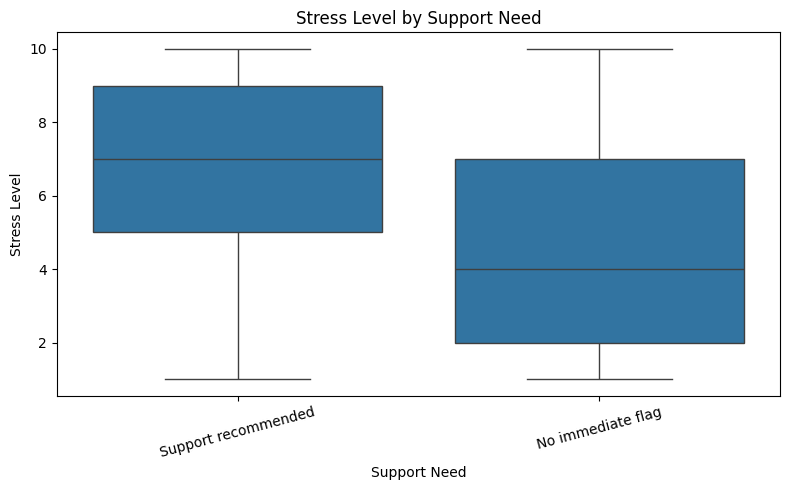

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="support_need", y="stress_level")

plt.title("Stress Level by Support Need")
plt.xlabel("Support Need")
plt.ylabel("Stress Level")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### **What does this Box Plot tell us?**

* **Higher Stress = More Support Needed:** Students labeled under **'Support recommended'** generally show significantly higher stress levels compared to those marked as **'No immediate flag'**.
* **Clear Differences:** The middle line (median) and the entire box for "Support recommended" are positioned much higher on the graph, meaning most of these students are experiencing severe, high-level stress.
* **Why it matters:** This plot confirms that the **support_need** categorization is doing a great job of identifying and flagging the students who are under the most pressure and need help.

## **Correlation Heatmap**

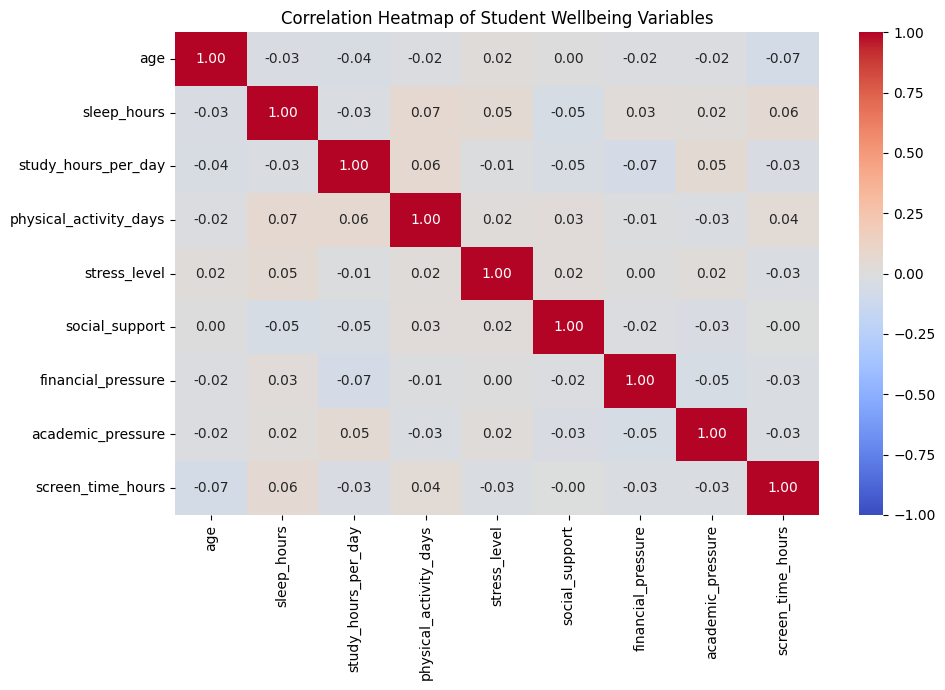

In [ ]:
numeric_cols = [
    "age", "sleep_hours", "study_hours_per_day",
    "physical_activity_days", "stress_level",
    "social_support", "financial_pressure",
    "academic_pressure", "screen_time_hours"
]

plt.figure(figsize=(10, 7))

correlation = df[numeric_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Student Wellbeing Variables")
plt.tight_layout()
plt.show()

### **What does this Correlation Heatmap tell us?**

Correlation measures how strongly two variables move together, ranging from **-1.00** (perfect opposite relationship) to **+1.00** (perfect identical relationship).

Here are the key takeaways from the heatmap:

* **Weak Relationships Overall:** Almost all correlation values are very close to `0` (mostly between `-0.05` and `+0.07`). This means there are **no strong linear relationships** between lifestyle choices (like study hours, sleep, or screen time) and pressures/stress levels in this dataset.
* **Stress, Pressures, and Support:** Even factors we expect to be heavily linked (like `academic_pressure` or `financial_pressure` with `stress_level`, or `social_support` helping reduce stress) show very weak correlations.
* **What this implies:** Because this is a synthetic dataset, the variables have likely been generated independently of each other. In a real-world scenario, you would expect to see stronger relationships (e.g., higher pressure correlating with higher stress, or more sleep correlating with lower stress).

## **Sleep Hours vs Stress Level — Scatter Plot**

### **What does this Scatter Plot tell us? (Simple Summary)**

* **No Clear Trend (No Correlation):** The dots are scattered everywhere like a cloud. This shows that there is **no clear pattern** linking a student's sleep hours directly to their stress level (e.g., sleeping more doesn't automatically mean lower stress in this dataset).
* **Perfect Separation by Support Need (The Colors):** Even though sleep and stress don't correlate, the colors show a clear boundary:
  * **Orange dots (Support recommended):** Grouped entirely at the top (Stress levels 6 to 10).
  * **Blue dots (No immediate flag):** Grouped entirely at the bottom (Stress levels 1 to 5).
* **Takeaway:** This confirms that the recommended support is determined directly by a student's overall stress level threshold, regardless of how many hours they sleep.

# 2.**Data Preprocessing and Feature engineering**





In [ ]:
# Define X and y before identifying feature types
X = df.drop(columns=["student_id", "support_need"])
y = df["support_need"]

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_cols)

print("\nNumerical features:")
print(numerical_cols)

Categorical features:
['gender', 'district', 'residence', 'mental_health_awareness']

Numerical features:
['age', 'sleep_hours', 'study_hours_per_day', 'physical_activity_days', 'stress_level', 'social_support', 'financial_pressure', 'academic_pressure', 'screen_time_hours']


# Converting the Categorical Variables to numerical

In [ ]:
# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")
preprocessor


Preprocessing pipeline created successfully.


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['age', 'sleep_hours', 'study_hours_per_day',
                                  'physical_activity_days', 'stress_level',
                                  'social_support', 'financial_pressure',
                                  'academic_pressure', 'screen_time_hours']),
                                ('cat',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'district', 'residence',
                                  'mental_health_awareness'])])

### # Separate input features (X) and target (y)

In [ ]:

# Remove the identifier and target column from the inputs
X = df.drop(columns=["student_id", "support_need"])

# Select the column we want to predict
y = df["support_need"]

# Check the results
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(X.columns.tolist())

print("\nTarget categories:")
print(y.unique())

Input features shape: (800, 13)
Target shape: (800,)

Input feature columns:
['age', 'gender', 'district', 'residence', 'sleep_hours', 'study_hours_per_day', 'physical_activity_days', 'stress_level', 'social_support', 'financial_pressure', 'academic_pressure', 'screen_time_hours', 'mental_health_awareness']

Target categories:
['Support recommended' 'No immediate flag']


## **Split data: 80% training and 20% testing**

In [ ]:
# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (640, 13)
Testing features: (160, 13)
Training target: (640,)
Testing target: (160,)


In [ ]:

# Learn preprocessing from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (640, 27)
Processed testing shape: (160, 27)


#**Model Development**

In [ ]:
## Create the Logistic Regression model
model = LogisticRegression(random_state=42, max_iter=2000)

# Train the model using the processed training data
model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## Make Prediction in Test Data

In [ ]:

# Predict the support category for the test data
y_pred = model.predict(X_test_processed)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Support Need": y_test.values,
    "Predicted Support Need": y_pred
})

display(results.head(10))


,Actual Support Need,Predicted Support Need
0,Support recommended,Support recommended
1,No immediate flag,No immediate flag
2,No immediate flag,No immediate flag
3,Support recommended,Support recommended
4,Support recommended,Support recommended
5,No immediate flag,Support recommended
6,Support recommended,Support recommended
7,No immediate flag,No immediate flag
8,No immediate flag,No immediate flag
9,Support recommended,Support recommended


# **Actual and Predicted Value**

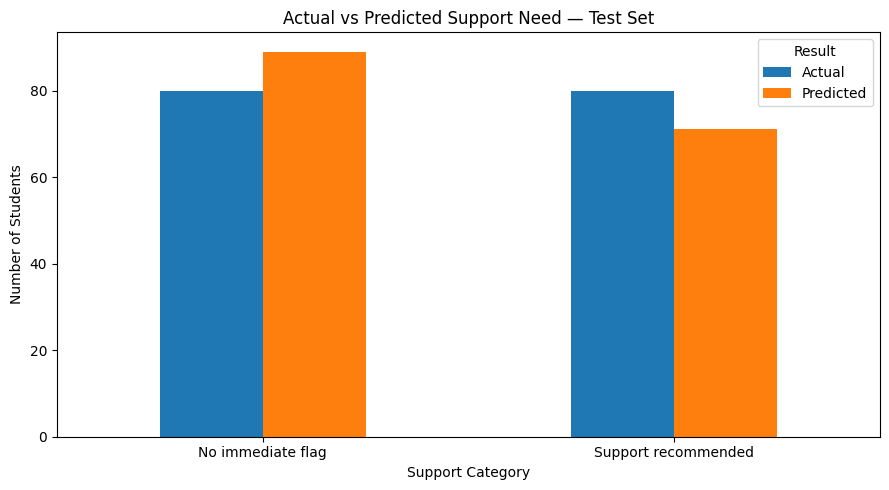

In [ ]:

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

counts = pd.DataFrame({
    "Actual": comparison["Actual"].value_counts(),
    "Predicted": comparison["Predicted"].value_counts()
}).reindex(["No immediate flag", "Support recommended"])

counts.plot(kind="bar", figsize=(9, 5))

plt.title("Actual vs Predicted Support Need — Test Set")
plt.xlabel("Support Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.legend(title="Result")
plt.tight_layout()
plt.show()


### **What does the Actual vs. Predicted Chart tell us?**

* **Balanced Dataset:** In the real test set, there are exactly **80 students** who need support and **80 students** who do not (represented by the blue bars).
* **Slight Under-prediction of Risk:** Our model predicted **71 students** for "Support recommended" (when there are actually 80) and predicted **89 students** for "No immediate flag" (when there are actually 80).
* **Takeaway:** This shows the model is slightly conservative or cautious—it missed predicting a few students who actually needed support, labeling them as safe instead. This is a common pattern in baseline classifiers that can be fine-tuned depending on how critical it is to catch every single student in need (sensitivity).

## Evaluation metrics

In [ ]:
# Define the positive class
positive_label = "Support recommended"

# Calculate evaluation metrics
y_probability = model.predict_proba(X_test_processed)

# Find the probability column corresponding to the positive class
positive_index = list(model.classes_).index(positive_label)
positive_probability = y_probability[:, positive_index]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(
    (y_test == positive_label).astype(int),
    positive_probability
)
precision = precision_score(
    y_test, y_pred, pos_label=positive_label, zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label=positive_label, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, pos_label=positive_label, zero_division=0
)

# Create a professional evaluation table
evaluation_table = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "ROC-AUC",
        "Precision",
        "Recall (Sensitivity)",
        "F1-Score"
    ],
    "Score (%)": [
        accuracy * 100,
        roc_auc * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

display(
    evaluation_table.style
    .format({"Score (%)": "{:.2f}%"})
    .set_caption("Logistic Regression Model Evaluation Results")
    .hide(axis="index")
)


Evaluation Metric,Score (%)
Accuracy,73.12%
ROC-AUC,79.52%
Precision,76.06%
Recall (Sensitivity),67.50%
F1-Score,71.52%


# **Confusion Matrix**

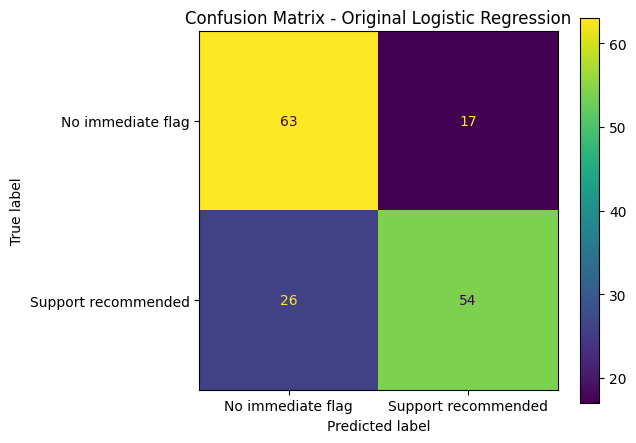

In [ ]:
# Plot confusion matrix for the original model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["No immediate flag", "Support recommended"],
    values_format="d"
)

plt.title("Confusion Matrix - Original Logistic Regression")
plt.tight_layout()
plt.show()

### **How to read this Confusion Matrix**

A **Confusion Matrix** shows how well the model did by comparing its predictions with the actual truth:

* **Correct Decisions (The Diagonal):**
  * **63 True Negatives (Top-Left):** The model correctly predicted "No immediate flag" for 63 students who actually did not need support.
  * **54 True Positives (Bottom-Right):** The model correctly predicted "Support recommended" for 54 students who actually did need support.

* **Errors (The Off-Diagonal):**
  * **17 False Alarms (Top-Right):** The model predicted "Support recommended" for 17 students, but they actually did not need any immediate support.
  * **26 Missed Cases (Bottom-Left):** This is the most critical error—the model predicted "No immediate flag" for 26 students who actually did need support.

**Takeaway:** The model is highly accurate overall, but it is slightly more likely to miss students who need help (26 misses) than it is to generate false alarms (17 false alarms).

# Saving the Model

In [ ]:
# Save the trained original Logistic Regression model
joblib.dump(model, "student_wellbeing_model.pkl")

# Save the synthetic dataset
df.to_csv("student_wellbeing_data.csv", index=False)

print("Model and dataset saved successfully!")

Model and dataset saved successfully!
